# 03 — `numpy` (Simulasi Vektorisasi, Aljabar Linear, Rantai Markov)
**Mata Kuliah:** Probabilitas dan Statistika | **Nama / NIM:** ________

NumPy membuat simulasi jutaan percobaan berjalan dalam hitungan detik berkat **vektorisasi** (tanpa loop Python), serta menyediakan aljabar linear untuk rantai Markov dan matriks kovarians.

## 1. Eksplorasi Library
| Fungsi / modul | Kegunaan |
|---|---|
| `np.random.default_rng(seed)` | Generator modern (reproducible) |
| `rng.integers`, `rng.random`, `rng.choice` | Bilangan acak diskrit/kontinu, sampling dengan/tanpa pengembalian |
| `rng.binomial/poisson/geometric/hypergeometric/multinomial` | Sampel distribusi diskrit |
| `rng.normal/uniform/exponential/gamma/weibull/pareto/beta` | Sampel distribusi kontinu |
| `rng.multivariate_normal` | Distribusi normal multivariat |
| `np.mean/var/std/percentile/cov/corrcoef` | Statistik deskriptif |
| `np.unique(return_counts=True)`, `np.histogram`, `np.cumsum` | Frekuensi, PMF/CDF empiris |
| `np.linalg.eig`, `np.linalg.matrix_power` | Rantai Markov |

In [1]:
import numpy as np, math
import matplotlib.pyplot as plt
rng=np.random.default_rng(42)

x=rng.integers(1,7,size=10)           # 10 lemparan dadu
print("dadu       :",x)
print("unik+count :",np.unique(x,return_counts=True))
print("normal     :",rng.normal(0,1,3).round(3))
print("binomial   :",rng.binomial(10,.2,5))
print("choice     :",rng.choice(['A','B','C'],size=6,p=[.5,.3,.2]))
print("mean,var   :",x.mean(),x.var(ddof=1))
print("persentil  :",np.percentile(x,[25,50,75]))

dadu       : [1 5 4 3 3 6 1 5 2 1]
unik+count : (array([1, 2, 3, 4, 5, 6]), array([3, 1, 2, 1, 2, 1]))
normal     : [-1.302  0.128 -0.316]
binomial   : [1 2 1 4 2]
choice     : ['C' 'A' 'A' 'B' 'A' 'C']
mean,var   : 3.1 3.433333333333333
persentil  : [1.25 3.   4.75]


## 2. Implementasi pada Permasalahan Probabilitas
### Soal 2.1 — Dua dadu, 5 juta percobaan (vektorisasi)
P(jumlah=8) = 5/36 ≈ 0,1389. Bandingkan hasil dan waktu.

P(sum=8) sim : 0.13878  teori 0.13889   waktu 0.08s


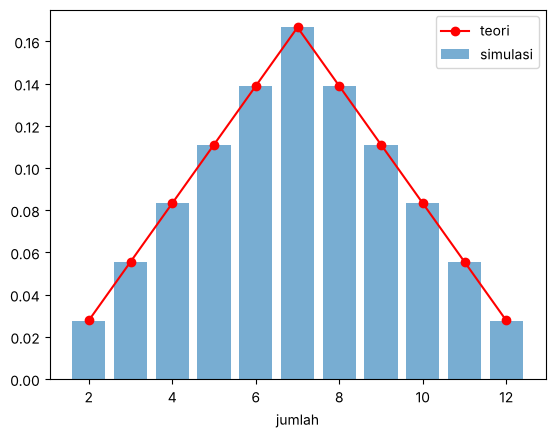

In [2]:
import time
N=5_000_000
t=time.time()
d1=rng.integers(1,7,N); d2=rng.integers(1,7,N)
s=d1+d2
print("P(sum=8) sim :",(s==8).mean().round(5)," teori",round(5/36,5), f"  waktu {time.time()-t:.2f}s")
# PMF empiris seluruh jumlah
v,c=np.unique(s,return_counts=True)
teori=np.array([6-abs(k-7) for k in v])/36
plt.bar(v,c/N,alpha=.6,label="simulasi"); plt.plot(v,teori,'ro-',label="teori"); plt.legend(); plt.xlabel("jumlah"); plt.show()

**Interpretasi:** 5 juta percobaan selesai dalam sepersekian detik (jauh lebih cepat dari loop `random` di notebook 02), dan PMF empiris berbentuk segitiga persis seperti teori (7 paling mungkin = 6/36).

### Soal 2.2 — Probabilitas bersyarat & independensi dengan *boolean mask*
Dari simulasi di atas: hitung P(sum=8 | d1 genap) (teori 1/6) dan uji independensi P(A∩B) vs P(A)P(B).

In [3]:
A=(s==8); B=(d1%2==0)
print("P(A)        =",A.mean().round(4))
print("P(B)        =",B.mean().round(4))
print("P(A|B)      =",A[B].mean().round(4)," teori",round(1/6,4))
print("P(A∩B)      =",(A&B).mean().round(4)," vs P(A)P(B)=",(A.mean()*B.mean()).round(4))

P(A)        = 0.1388
P(B)        = 0.5003
P(A|B)      = 0.1664  teori 0.1667
P(A∩B)      = 0.0832  vs P(A)P(B)= 0.0694


**Interpretasi:** P(A|B)≈0,1667 ≠ P(A)≈0,1389, dan P(A∩B)≈0,0833 ≠ P(A)P(B)≈0,0694 → A dan B tidak independen. Teknik `A[B]` (menyaring dengan mask) adalah cara efisien menghitung peluang bersyarat dari data simulasi.

### Soal 2.3 — Bayes pada populasi 10 juta (alarm IDS)
Prior 1%, TPR 99%, FPR 5%. Teori P(serangan|alarm)=1/6≈0,1667.

In [4]:
N=10_000_000
serang=rng.random(N)<0.01
alarm=np.where(serang, rng.random(N)<0.99, rng.random(N)<0.05)
print("alarm       :",alarm.sum())
print("P(serang|alarm) sim :",serang[alarm].mean().round(4)," teori 0.1667")
print("P(alarm|serang)     :",alarm[serang].mean().round(4))
print("P(serang|tanpa alarm):",serang[~alarm].mean().round(6))

alarm       : 593902
P(serang|alarm) sim : 0.1667  teori 0.1667
P(alarm|serang)     : 0.9899
P(serang|tanpa alarm): 0.000107


**Interpretasi:** Hanya ±1/6 alarm yang benar, tetapi bila tidak ada alarm, peluang ada serangan sangat kecil (~0,0001). Alarm tetap berguna untuk menyaring, hanya saja butuh verifikasi tahap kedua.

### Soal 2.4 — Rantai Markov: perilaku pengguna antar halaman
Dua keadaan: 0=Beranda, 1=Produk. Matriks transisi P=[[0,9; 0,1],[0,5; 0,5]]. Cari distribusi stasioner π (πP=π) lewat **eigenvector**, **pangkat matriks**, dan **simulasi**.
**Manual:** π₀·0,1=π₁·0,5 → π=(5/6, 1/6).

eigenvalue      : [1. +0.j 0.4+0.j]
pi (eigenvector): [0.8333 0.1667]  teori (0.8333333333333334, 0.16666666666666666)
P^50 baris 0    : [0.8333 0.1667]


proporsi kunjungan sim: [0.8334 0.1666]


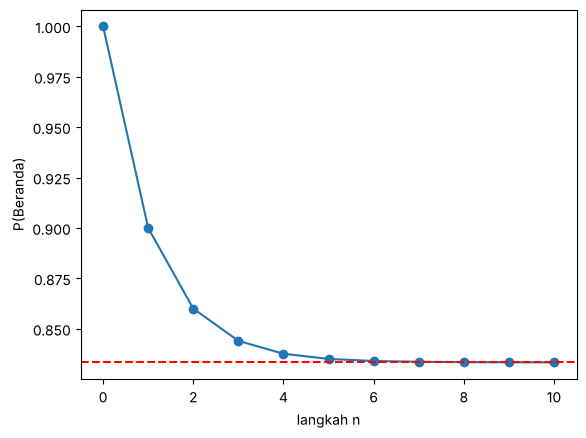

In [5]:
P=np.array([[0.9,0.1],[0.5,0.5]])
w,v=np.linalg.eig(P.T)
pi=np.real(v[:,np.isclose(w,1)].ravel()); pi/=pi.sum()
print("eigenvalue      :",w.round(4))
print("pi (eigenvector):",pi.round(4)," teori",(5/6,1/6))
print("P^50 baris 0    :",np.linalg.matrix_power(P,50)[0].round(4))

# simulasi 1 rantai panjang
steps=300_000; state=0; visit=np.zeros(2)
u=rng.random(steps)
for k in range(steps):
    state=0 if u[k]<P[state,0] else 1
    visit[state]+=1
print("proporsi kunjungan sim:",(visit/steps).round(4))
# P(n) dari awal Beranda
dist=[np.array([1,0])@np.linalg.matrix_power(P,n) for n in range(0,11)]
plt.plot([d[0] for d in dist],'o-'); plt.axhline(pi[0],ls='--',c='r'); plt.xlabel("langkah n"); plt.ylabel("P(Beranda)"); plt.show()

**Interpretasi:** Ketiga metode memberi π≈(0,833; 0,167): dalam jangka panjang pengguna berada di Beranda 83% waktu, **tidak bergantung** pada halaman awal. Eigenvalue kedua (0,4) menentukan kecepatan konvergensi — grafik menunjukkan mendekati stasioner dalam ±5–6 langkah. Konsep ini dasar PageRank.

## 3. Implementasi pada Distribusi Probabilitas
### Soal 3.1 — Ringkasan banyak distribusi (rata-rata & varians: teori vs sampel)

In [6]:
N=1_000_000
D={
 "Binomial(20,.3)":  (rng.binomial(20,.3,N), 6,      4.2),
 "Poisson(4)":       (rng.poisson(4,N),      4,      4),
 "Geometrik(.25)":   (rng.geometric(.25,N),  4,      12),
 "Hipergeom(50,8,10)":(rng.hypergeometric(8,42,10,N),1.6, 10*(8/50)*(42/50)*(40/49)),
 "Uniform(0,10)":    (rng.uniform(0,10,N),   5,      100/12),
 "Normal(100,15)":   (rng.normal(100,15,N),  100,    225),
 "Eksponensial(λ=.5)":(rng.exponential(2,N), 2,      4),
 "Gamma(k=3,θ=2)":   (rng.gamma(3,2,N),      6,      12),
 "Weibull(k=1.5,λ=100)":(100*rng.weibull(1.5,N), 100*math.gamma(1+1/1.5), 100**2*(math.gamma(1+2/1.5)-math.gamma(1+1/1.5)**2)),
 "Beta(2,5)":        (rng.beta(2,5,N),       2/7,    10/(49*8)),
}
print(f"{'Distribusi':24}{'mean sim':>10}{'mean teori':>12}{'var sim':>10}{'var teori':>11}")
for k,(x,m,v) in D.items(): print(f"{k:24}{x.mean():10.3f}{m:12.3f}{x.var():10.3f}{v:11.3f}")

Distribusi                mean sim  mean teori   var sim  var teori
Binomial(20,.3)              5.999       6.000     4.204      4.200
Poisson(4)                   4.002       4.000     4.002      4.000
Geometrik(.25)               3.993       4.000    11.972     12.000
Hipergeom(50,8,10)           1.599       1.600     1.096      1.097
Uniform(0,10)                4.995       5.000     8.337      8.333
Normal(100,15)             100.021     100.000   224.785    225.000
Eksponensial(λ=.5)           2.000       2.000     3.998      4.000
Gamma(k=3,θ=2)               5.999       6.000    12.025     12.000
Weibull(k=1.5,λ=100)        90.220      90.275  3746.171   3756.903
Beta(2,5)                    0.286       0.286     0.026      0.026


**Interpretasi:** Semua rata-rata dan varians sampel (N=10⁶) cocok dengan rumus teori hingga 2–3 angka bermakna. Perhatikan parameterisasi NumPy: `exponential(scale=1/λ)`, `gamma(shape, scale)`, dan `weibull` hanya shape sehingga perlu dikalikan skala λ.

### Soal 3.2 — Binomial → Poisson dan Binomial → Normal (visualisasi pendekatan)

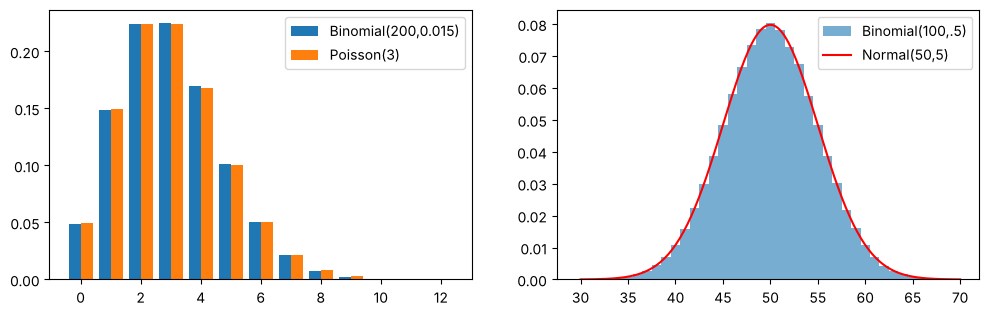

P(X<=45) binom: 0.1838  normal(koreksi kontinuitas 45.5): 0.18405


In [7]:
from math import comb, exp, factorial, sqrt, pi
N=500_000
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
# a) n=200,p=0.015 -> Poisson(3)
b=rng.binomial(200,.015,N); ks=np.arange(0,13)
ax[0].bar(ks-.2,[ (b==k).mean() for k in ks],.4,label="Binomial(200,0.015)")
ax[0].bar(ks+.2,[exp(-3)*3**k/factorial(k) for k in ks],.4,label="Poisson(3)"); ax[0].legend()
# b) n=100,p=.5 -> Normal(50,5)
b2=rng.binomial(100,.5,N)
ax[1].hist(b2,bins=np.arange(30,71)-.5,density=True,alpha=.6,label="Binomial(100,.5)")
xs=np.linspace(30,70,200); ax[1].plot(xs,np.exp(-(xs-50)**2/50)/sqrt(2*pi*25),'r',label="Normal(50,5)"); ax[1].legend()
plt.show()
print("P(X<=45) binom:", (b2<=45).mean().round(4), " normal(koreksi kontinuitas 45.5):", 0.5*(1+math.erf((45.5-50)/(5*sqrt(2)))).__round__(4))

**Interpretasi:** Untuk n besar-p kecil Binomial ≈ Poisson(np); untuk np(1−p) besar Binomial ≈ Normal. Dengan **koreksi kontinuitas** (45,5), pendekatan Normal untuk P(X≤45) sangat dekat dengan nilai Binomial (≈0,184).

### Soal 3.3 — Normal multivariat: latensi dan ukuran paket (distribusi gabungan)
(latensi, ukuran) ~ N(μ=(100, 500), Σ) dengan korelasi 0,6. Hitung kovarians, korelasi, dan regresi kondisional E[latensi | ukuran > 600].

cov sampel:
 [[  99.7  479.6]
 [ 479.6 6416.2]]
cov teori :
 [[ 100.  480.]
 [ 480. 6400.]]
corr sampel: 0.6
E[latensi|ukuran>600] = 110.36  vs tanpa syarat = 100.02


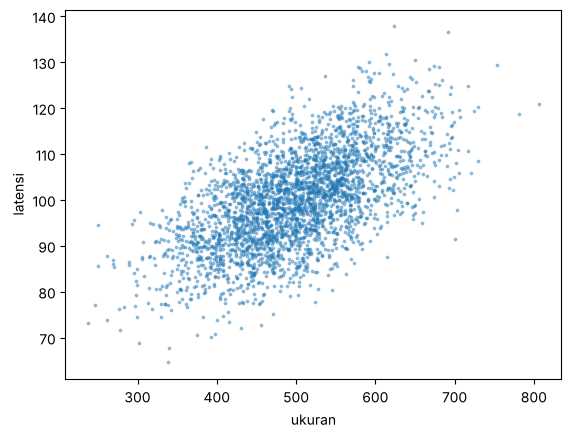

In [8]:
mu=[100,500]; sd=[10,80]; rho=.6
cov=[[sd[0]**2,rho*sd[0]*sd[1]],[rho*sd[0]*sd[1],sd[1]**2]]
X=rng.multivariate_normal(mu,cov,200_000)
print("cov sampel:\n",np.cov(X.T).round(1)); print("cov teori :\n",np.array(cov))
print("corr sampel:",np.corrcoef(X.T)[0,1].round(3))
m=X[:,1]>600
print("E[latensi|ukuran>600] =",X[m,0].mean().round(2)," vs tanpa syarat =",X[:,0].mean().round(2))
plt.scatter(X[:3000,1],X[:3000,0],s=3,alpha=.4); plt.xlabel("ukuran"); plt.ylabel("latensi"); plt.show()

**Interpretasi:** Korelasi sampel ≈0,6 sesuai parameter. Paket besar cenderung berlatensi lebih tinggi (rata-rata kondisional >100 ms) — informasi yang tidak tampak jika hanya melihat distribusi marginal.

## 4. Pengembangan Contoh Permasalahan
### Soal 4.1 — Keandalan sistem seri vs paralel (Eksponensial)
3 komponen independen, umur ~ Exp(rata-rata 1000 jam). P(sistem hidup > 1000 jam)?
**Manual:** tiap komponen R=e⁻¹≈0,3679. Seri: R³=e⁻³≈0,0498. Paralel: 1−(1−e⁻¹)³≈0,7474.

Seri    sim: 0.0499  teori 0.0498 | E[umur] 333.2 (333.3)
Paralel sim: 0.7474  teori 0.7474 | E[umur] 1833.7 (1833.3)


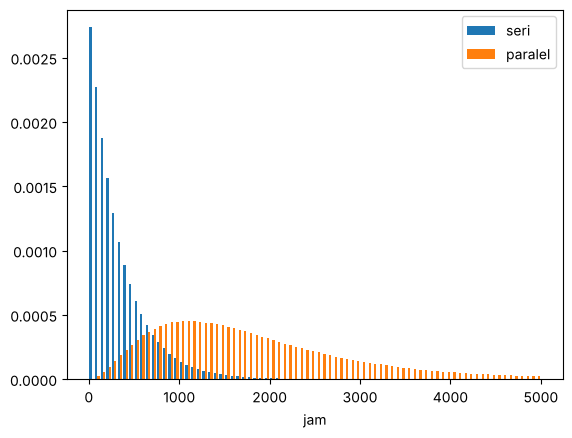

In [9]:
N=2_000_000
L=rng.exponential(1000,(N,3))
seri=L.min(axis=1); paralel=L.max(axis=1)
r=math.exp(-1)
print("Seri    sim:",(seri>1000).mean().round(4)," teori",round(r**3,4),"| E[umur]",seri.mean().round(1),"(333.3)")
print("Paralel sim:",(paralel>1000).mean().round(4)," teori",round(1-(1-r)**3,4),"| E[umur]",paralel.mean().round(1),"(1833.3)")
plt.hist([seri,paralel],bins=80,range=(0,5000),density=True,label=["seri","paralel"]); plt.legend(); plt.xlabel("jam"); plt.show()

**Interpretasi:** Sistem seri (semua harus hidup) sangat rapuh: hanya ±5% bertahan 1000 jam, umur rata-rata 333 jam. Redundansi paralel menaikkannya menjadi ±75% dengan umur rata-rata 1833 jam (=1000·(1+½+⅓)). Dasar desain *fault-tolerance* (RAID, replikasi server).

### Soal 4.2 — Pertidaksamaan Markov & Chebyshev vs nilai sebenarnya
Waktu respons T ~ Exp(rata-rata 2 dtk, var 4). Bandingkan P(T≥6) sebenarnya (e⁻³≈0,0498) dengan batas Markov (E/6) dan Chebyshev (σ²/(6−2)²).

In [10]:
T=rng.exponential(2,3_000_000); a=6
print("P(T>=6) sebenarnya :",(T>=a).mean().round(4),"(teori",round(math.exp(-3),4),")")
print("Batas Markov       :",round(2/a,4))
print("Batas Chebyshev    :",round(4/(a-2)**2,4))
ks=np.arange(1,8); print("P(|T-2|>=k*sd) :",[float(round((abs(T-2)>=k*2).mean(),4)) for k in ks])
print("Batas 1/k^2         :",[float(round(1/k**2,4)) for k in ks])

P(T>=6) sebenarnya : 0.0497 (teori 0.0498 )
Batas Markov       : 0.3333
Batas Chebyshev    : 0.25
P(|T-2|>=k*sd) : [0.1352, 0.0497, 0.0183, 0.0067, 0.0025, 0.0009, 0.0004]
Batas 1/k^2         : [1.0, 0.25, 0.1111, 0.0625, 0.04, 0.0278, 0.0204]


**Interpretasi:** Batas Markov (0,333) dan Chebyshev (0,25) benar tetapi **sangat longgar** dibanding nilai sebenarnya 0,05. Pertidaksamaan ini berguna saat distribusi tidak diketahui, tetapi bila distribusi diketahui hitung langsung.

### Soal 4.3 — Bootstrap: selang kepercayaan untuk median waktu respons
Diberi 40 data waktu respons (log-normal). Estimasi median dan CI 95% dengan resampling 10.000 kali.

median sampel : 128.0  | median teori e^5 = 148.4
CI95 bootstrap: [104.7, 151.2]


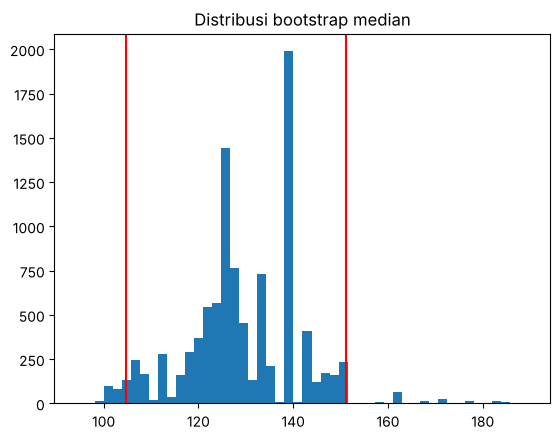

In [11]:
data=rng.lognormal(mean=5,sigma=.6,size=40)
boot=np.array([np.median(rng.choice(data,40,replace=True)) for _ in range(10_000)])
lo,hi=np.percentile(boot,[2.5,97.5])
print("median sampel :",np.median(data).round(1)," | median teori e^5 =",round(math.e**5,1))
print("CI95 bootstrap: [%.1f, %.1f]"%(lo,hi))
plt.hist(boot,bins=50); plt.axvline(lo,c='r'); plt.axvline(hi,c='r'); plt.title("Distribusi bootstrap median"); plt.show()

**Interpretasi:** Bootstrap memberi ketidakpastian estimasi tanpa asumsi distribusi tertentu. Lebar CI mencerminkan ukuran sampel kecil (n=40); menambah data mempersempitnya sebanding 1/√n.

## Kesimpulan
1. NumPy mempercepat simulasi puluhan–ratusan kali dibanding loop Python dan memudahkan peluang bersyarat lewat *mask*.
2. `linalg.eig` dan `matrix_power` memecahkan rantai Markov secara analitik, hasilnya cocok dengan simulasi.
3. Waspadai parameterisasi (`scale=1/λ`, `weibull` tanpa skala). Untuk PMF/CDF/kuantil/uji statistik gunakan **SciPy** (notebook 04).